# Imports

In [1]:
import matplotlib.pyplot as plt
import os
import scipy.io as sio
import numpy as np
from matplotlib.lines import Line2D
import pickle

# Functions

In [2]:
# Method for converting spike times to a binary vector as required by Giovanni's implementation of the PGAS algorithm
def spike_times_2_binary(spike_times,time_stamps):
    # initialize the binary vector
    binary_vector = np.zeros(len(time_stamps), dtype=int)

    # get event times within the time_stamps ends
    good_spike_times = spike_times[(spike_times >= time_stamps[0]) & (spike_times <= time_stamps[-1])]
    
    # Find the nearest element in 'a' that is less than the elements in 'b'
    for event_time in good_spike_times:
        # Find indices where 'a' is less than 'event_time'
        valid_indices = np.where(time_stamps < event_time)[0]
        if valid_indices.size > 0:
            nearest_index = valid_indices[-1]  # Taking the last valid index
            binary_vector[nearest_index] += 1

    return binary_vector

In [3]:
# For opening the janelia datasets
def open_Janelia_1(j_path):
    all_data = sio.loadmat(j_path)
    dff = all_data['dff']
    time_stamps = all_data['time_stamps']
    spike_times = all_data['ap_times'] 

    return time_stamps, dff, spike_times

In [4]:
# For unrolling the PGAS and PGBAR output files
def unroll_dat_files(dat_file):
    '''
    PGAS contain the following output variables:
    -B = basline drift, brownian
    -S = discretized spike number per time bin
    -C = "calcium" value - really more akin to a DFF-like metric
    -Y = original data (not included in PGBAR output)
    '''
    

    data = np.genfromtxt(dat_file, delimiter=',', skip_header=1)
    #Dealing out data
    index = data[:,0]
    B = data[:,2]
    S = data[:,3]
    C = data[:,4]
    
    #Note that files produced by PGBAR (rather than the more general PGAS) lack Y - for now not including it
    try:
        Y = data[:,5]
    except:
        Y = np.nan
    
    return index,B,S,C,Y

In [5]:
def load_sim_outputs(tags):
    dffs = []
    dffs_interp = []
    ca_states = []
    ca_in_states = []
    bca_states = []
    all_states = []
    for tag_dir in tags:

        dff = np.load(os.path.join(tag_dir, "dff.npy"))
        dffs.append(dff)

        if "la_model" in tag_dir:
            with open(os.path.join(tag_dir, "states.npy"), 'rb') as file:
                states = pickle.load(file)
            ca_states.append(states['Ca'])
            ca_in_states.append(states['Ca_in'])
            bca_states.append(states['BCa'])
            all_states.append(states)
            
        else:
            states = np.load(os.path.join(tag_dir, "states.npy"))
            ca_states.append(states[:, 9])
            ca_in_states.append(states[:, 10])
            bca_states.append(states[:, 11])
            all_states.append(states)

            dff_interp = np.load(os.path.join(tag_dir, "dff_interp.npy"))
            dffs_interp.append(dff_interp)

        time = np.load(os.path.join(tag_dir, "time.npy"))
        spike_times = np.load(os.path.join(tag_dir, "spike_times.npy"))

    return dffs, dffs_interp, ca_states, all_states, time, spike_times

# Panels A, D, and E

### Panel A

In [6]:
tag_dir = "sim_output_supp_overlay_final"
tag2 = "pyr_f"
tag3 = "pyr_mod_pv_f"
tag4 = "SNR_02_5"
tags = sorted([os.path.join(tag_dir, x) for x in os.listdir(tag_dir) if tag2 in x or tag3 in x])
tags

['sim_output_supp_overlay_final/pyr_full_model_[G]_050',
 'sim_output_supp_overlay_final/pyr_mod_pv_full_model_[G]_050']

In [7]:
dffs, dffs_interp, ca_states, all_states, time_interp, spike_times = load_sim_outputs(tags)

In [8]:
dffs_mod = [dffs_interp[0], dffs_interp[1]]

Text(405.0, 0.45999999999999996, '0.2 norm. ΔF/F')

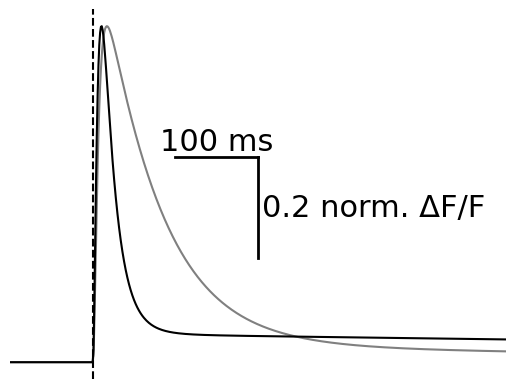

In [9]:
time_np = np.arange(0, 1 + 1e-3, 1e-3)
plt.plot(dffs_mod[0] / max(dffs_mod[0]), label = "Simulated Pyramidal Cell", color="gray")
plt.plot(dffs_mod[1] / max(dffs_mod[1]), label = "Simplified Model--SNR 5", color="black")
plt.axvline(x = spike_times[0] * 1000, linestyle="--", color = "black")
plt.xlim([100, 700])

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])
ax.set_yticks([])

xlim = ax.get_xlim()
ylim = ax.get_ylim()

x_len = 100      # 100 ms
y_len = 0.3      # 0.1 DF/F

# move closer to traces
x0 = xlim[1] - 0.5 * (xlim[1] - xlim[0])
y0 = ylim[1] - 0.4 * (ylim[1] - ylim[0])

# horizontal time bar
ax.plot([x0-x_len, x0], [y0, y0], color='k', lw=2)

# vertical DF/F bar
ax.plot([x0, x0], [y0, y0-y_len], color='k', lw=2)

ax.text(x0-x_len/2, y0+0.02, "100 ms", ha='center', fontsize=22)
ax.text(x0+5, y0-y_len/2, "0.2 norm. ΔF/F", va='center', fontsize=22)

#plt.savefig("plots2_local/panel_a2.pdf", format="pdf", bbox_inches="tight")
#plt.savefig("plots/panel_c2.pdf", format="pdf", bbox_inches="tight")

Text(405.0, 0.1373563745197458, '0.1 ΔF/F')

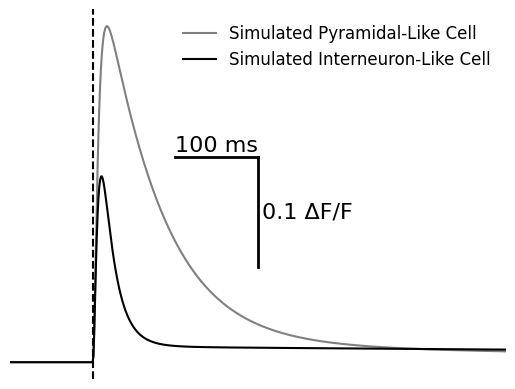

In [10]:
plt.plot(dffs_mod[0], label = "Simulated Pyramidal-Like Cell", color = "gray")
plt.plot(dffs_mod[1], label = "Simulated Interneuron-Like Cell", color = "black")
plt.axvline(x = spike_times[0] * 1000, linestyle="--", color = "black")
#plt.xlabel("Time (ms)")
plt.xlim([100, 700])
plt.legend(
    loc="upper right",
    frameon=False,
    fontsize=12
)
#plt.ylabel("DF/F")
#plt.axis('off')

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])
ax.set_yticks([])

xlim = ax.get_xlim()
ylim = ax.get_ylim()

x_len = 100      # 100 ms
y_len = 0.1     # 0.1 DF/F

# move closer to traces
x0 = xlim[1] - 0.5 * (xlim[1] - xlim[0])
y0 = ylim[1] - 0.4 * (ylim[1] - ylim[0])

# horizontal time bar
ax.plot([x0-x_len, x0], [y0, y0], color='k', lw=2)

# vertical DF/F bar
ax.plot([x0, x0], [y0, y0-y_len], color='k', lw=2)

ax.text(x0-x_len/2, y0+0.005, "100 ms", ha='center', fontsize=16)
ax.text(x0+5, y0-y_len/2, "0.1 ΔF/F", va='center', fontsize=16)

#plt.savefig("plots2_local/panel_d2.pdf", format="pdf", bbox_inches="tight")

### Panels D and E

In [11]:
tag_dir = "sim_output_supp_overlay_final"

#Pyramidal like tags
#tag2 = "pyr_f"
#tag3 = "pyr_n"

#Interneuron like tags
tag2 = "pyr_mod_pv_f"
tag3 = "pyr_mod_pv_n"

#Choose Snr
tag4 = "SNR_02_5"

tags = sorted([os.path.join(tag_dir, x) for x in os.listdir(tag_dir) if tag2 in x or tag3 in x and tag4 in x])
tags

['sim_output_supp_overlay_final/la_model_pyr_mod_pv_no_baseline_rerun_SNR_02_5',
 'sim_output_supp_overlay_final/pyr_mod_pv_full_model_[G]_050']

In [12]:
dffs, dffs_interp, ca_states, all_states, time_interp, spike_times = load_sim_outputs(tags)

In [13]:
dffs_mod = [dffs_interp[0], dffs[0]]

Text(405.0, 0.07865036234200143, '0.05 ΔF/F')

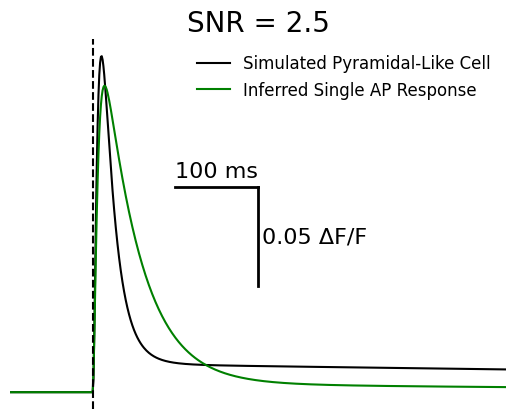

In [14]:
kernel_color = "gray"
if tag2 == "pyr_mod_pv_f":
    kernel_color = "black"
plt.plot(dffs_mod[0], label = "Simulated Pyramidal-Like Cell", color=kernel_color)
plt.plot(dffs_mod[1], label = "Inferred Single AP Response", color = "green")
plt.axvline(x = spike_times[0] * 1000, linestyle="--", color = "black")
#plt.xlabel("Time (ms)")
plt.xlim([100, 700])
plt.legend(
    loc="upper right",
    frameon=False,
    fontsize=12
)
#plt.ylabel("DF/F")
if tag4 == "SNR_02_5":
    plt.title("SNR = 2.5", fontsize=20)
else:
    plt.title("SNR = 5", fontsize=20)
#plt.axis('off')

ax = plt.gca()

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks([])
ax.set_yticks([])

xlim = ax.get_xlim()
ylim = ax.get_ylim()

x_len = 100      # 100 ms
y_len = 0.1     # 0.1 DF/F
if tag2 == "pyr_mod_pv_f":
    y_len = 0.05

# move closer to traces
x0 = xlim[1] - 0.5 * (xlim[1] - xlim[0])
y0 = ylim[1] - 0.4 * (ylim[1] - ylim[0])

# horizontal time bar
ax.plot([x0-x_len, x0], [y0, y0], color='k', lw=2)

# vertical DF/F bar
ax.plot([x0, x0], [y0, y0-y_len], color='k', lw=2)

ax.text(x0-x_len/2, y0+0.005, "100 ms", ha='center', fontsize=16)
scale_bar_label = "0.1 ΔF/F"
if tag2 == "pyr_mod_pv_f":
    scale_bar_label = "0.05 ΔF/F"
ax.text(x0+5, y0-y_len/2, scale_bar_label, va='center', fontsize=16)

#plt.savefig("plots2_local/panel_d2.pdf", format="pdf", bbox_inches="tight")

# Panels B and C

In [26]:
# Have to chose cell type as pyramidal or interneuron. (Anything other than pyramidal will treated as interneuron)
cell_type = "interneuron"

if cell_type == 'pyramidal':
    #For pyramidal like cell
    metric_tag = "pyr"
else:
    #For internueron like cell
    metric_tag = "pyr_mod_pv"

# Can use "SNR_02_5" or "SNR_05"
tag2 = "SNR_02_5"

if cell_type != 'pyramidal':
    if tag2 == "SNR_02_5":
        tag2 = "SNR_05"
    else:
        tag2 = "SNR_10"

tag3 = "full_sim_[G]_050"

posterior_dir = f"results/pgas_output/{metric_tag}_{tag3}_Hz_janelia_no_baseline_rerun_dat_{tag2}"
tag4 = ""
posterior_traj_files = [os.path.join(posterior_dir, x) for x in sorted(os.listdir(posterior_dir)) if metric_tag in x and
                                                          "traj_samples" in x and tag3 in x and tag4 in x and ".dat" in x]
posterior_traj_files

['results/pgas_output/pyr_mod_pv_full_sim_[G]_050_Hz_janelia_no_baseline_rerun_dat_SNR_05/traj_samples_pyr_mod_pv_full_sim_[G]_050_Hz_janelia_sraw_ms2_rsraw_bm0p02_trial0.dat']

In [27]:
data_dir = f"sim_mat_data_to_infer_final_{tag2}"

data_pth = os.path.join(data_dir, f"{metric_tag}_{tag3}_Hz_janelia" + ".mat")
print(os.path.exists(data_pth))
print(data_pth)

True
sim_mat_data_to_infer_final_SNR_05/pyr_mod_pv_full_sim_[G]_050_Hz_janelia.mat


In [28]:
#Getting the file information
# Get the directory where the script is located
script_dir = "/projects/sjanarthanan@xsede.org/code/Figshare_NM_GCaMP/supp_figure8"

data_stub = [data_pth]

sim_wk_dir = "results/pgas_output"

sim_stub = [posterior_traj_files[0]]

# Same spike train for both cell types
data_dir = os.path.join("all_sim_data", f"pyr_full_sim_final_[G]_050")

spike_times_pyr = np.load(os.path.join(data_dir, "spike_times.npy"))

#Load and process the inferences
recalc = True
if recalc:
    #initialize lists
    times = [];dffs = [];binary_spikes_list = [];spike_times_list=[]
    trajs = [];spks = [];S_samples = []
    trajs_ar = [];spks_ar = []; S_samples_ar = []
    avg_trajs = [];std_trajs = [];avg_spks = []
    avg_trajs_ar = [];std_trajs_ar = [];avg_spks_ar = []

    # sample spike latent state trajectory to show
    S_2_start = 409
    S_2_end = 499
    draws_to_show = 6
    selected_draws = np.arange(S_2_start, S_2_end, draws_to_show)

    for i in np.arange(len(data_stub)):
        #Get data
        print(i)
        print(data_stub[i])
        data_file = os.path.join(script_dir,data_stub[i])
        time,data_dff,spike_times = open_Janelia_1(data_file)
        times.append(time[0,:])
        dffs.append(data_dff[0,:])
        spike_times_list.append(spike_times_pyr)
        binary_spikes_list.append(spike_times_2_binary(spike_times_pyr,times[i]))
    
        # Getting the PGAS and PGBAR output
        pgas_file = os.path.join(script_dir,sim_stub[i])
        index, B, S, C, Y = unroll_dat_files(pgas_file)
        #pgbar_file = os.path.join(script_dir,pgbar_stub[i])
        #index_ar, B_ar, S_ar, C_ar, Y_ar = unroll_dat_files(pgbar_file)
        
        # Now reshaping for mean trajectories
        trajs.append((B + C).reshape((-1, np.sum(index == 0))).T)
        avg_trajs.append(np.mean(trajs[i][:, -100:], axis=1))
        std_trajs.append(np.std(trajs[i][:, -100:], axis=1))
        S_samples.append([S[index==draw].T for draw in selected_draws])
        #S_samples.append(S[index == S_2_show].T)
        spks.append(S.reshape((-1, np.sum(index == 0))).T)
        avg_spks.append(np.mean(spks[i][:, -100:], axis=1))


0
sim_mat_data_to_infer_final_SNR_05/pyr_mod_pv_full_sim_[G]_050_Hz_janelia.mat


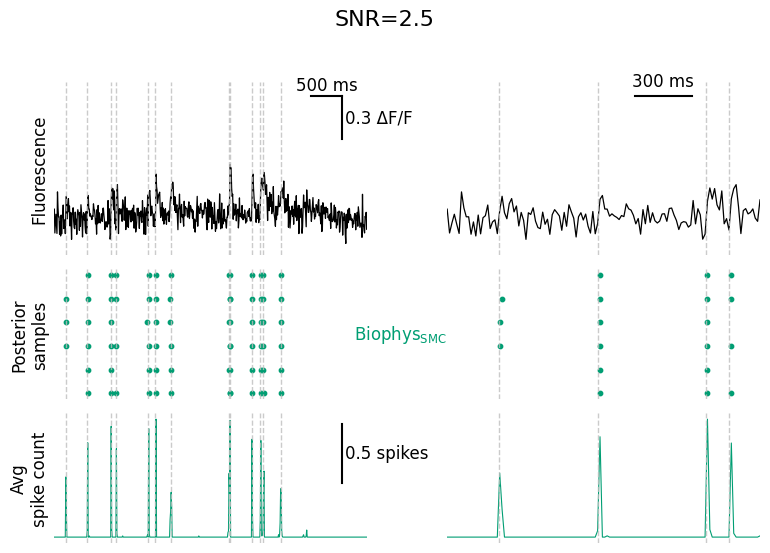

In [29]:
# =========================
# FINAL PLOT (Excitatory only, one segment, no Linear SMC)
# 3 rows x 2 columns: DF/F, posterior rasters, mean spike count
# Preserves correct posterior alignment by locking x-limits
# before adding extra artists (GT lines, scale bars, labels)
# =========================

# ---- Select dataset (0 = excitatory) ----
i = 0

# ---- Pull arrays as 1D ----
dff_1d = np.asarray(dffs[i]).squeeze().reshape(-1)
spk_mean_1d = np.asarray(avg_spks[i]).squeeze().reshape(-1)
t_1d = np.asarray(times[i]).squeeze().reshape(-1)

T = len(dff_1d)
assert len(spk_mean_1d) == T, "avg_spks length must match dff length"
assert len(t_1d) == T, "times length must match dff length"
dt = t_1d[1] - t_1d[0]

# ---- Windows (two columns) ----
new_dt = 0.008324649828372261
scale = 1/new_dt
#Worked for parv and pyr at 100uM [GCaMP] sim
full_start = int(6 * scale)
full_end = int(11 * scale)
window_start = int(6 * scale)
window_end = int(7.1 * scale)
wins = [slice(full_start, full_end), slice(window_start, window_end)]  # edit as desired; clipped safely below

# ---- Posterior draws to show ----
draws_to_show = 6

# ---- Lag ----
lag_bins = 0
t_shift = lag_bins * dt

# ---- Ground-truth spikes ----
plot_gt = True
gt_col = (0.75, 0.75, 0.75)
st = np.asarray(spike_times_list[i]).squeeze()
st = st.reshape(-1) if st.size else st

# ---- Extract posterior spike indices from full-length binned vectors ----
S_samples_idxs = [np.where(np.asarray(s_draw).squeeze().reshape(-1) >= 1)[0]
                  for s_draw in S_samples[i]]

# ---- Styling ----
dff_col = (0.6, 0.6, 0.6)   # gray full trace
spk_col = '#009E73'

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

fig, axes = plt.subplots(
    3, 2,
    figsize=(7.8, 5.6),
    sharex='col',
    gridspec_kw={'height_ratios': [1.2, 0.9, 0.9]}
)

fig.subplots_adjust(wspace=0.35)

# Store x-limits for later safe use
col_xlims = []

for col, win in enumerate(wins):
    # ---- Clip window to [0, T] ----
    start = 0 if win.start is None else max(0, win.start)
    stop = T if win.stop is None else min(T, win.stop)
    if stop <= start:
        raise ValueError(f"Empty window after clipping: {win} -> ({start},{stop})")
    win = slice(start, stop)

    x = t_1d[win]# - t_shift
    #print(x)

    # ========== Row 0: DF/F ==========
    trace_color = "black"
    if cell_type == 'pyramidal':
        trace_color = "gray"
    axes[0, col].plot(x, dff_1d[win], color=trace_color, lw=0.9)
    axes[0, col].set_ylim([-0.2, 1])

    # ========== Row 1: Posterior rasters ==========
    for trial_idx in range(min(draws_to_show, len(S_samples_idxs))):
        spk_idxs = S_samples_idxs[trial_idx]
        spk_idxs = spk_idxs[(spk_idxs >= win.start) & (spk_idxs < win.stop)]

        axes[1, col].scatter(
            t_1d[spk_idxs] - t_shift,
            np.full(spk_idxs.shape, -trial_idx * 0.2),
            color=spk_col,
            s=10
        )

    # ========== Row 2: Mean inferred spike count ==========
    axes[2, col].plot(x, spk_mean_1d[win], color=spk_col, lw=0.8)

    # ---- LOCK x-limits before adding GT lines / text / scale bars ----
    xmin = t_1d[win.start] - t_shift
    xmax = t_1d[win.stop - 1] - t_shift
    col_xlims.append((xmin, xmax))

    for r in range(3):
        axes[r, col].set_xlim(xmin, xmax)
        axes[r, col].autoscale(enable=False, axis='x')

    # ========== Optional GT spikes ==========
    if plot_gt and st.size > 0:
        good = (st >= t_1d[win.start]) & (st <= t_1d[win.stop - 1])
        for spike in st[good]:
            for r in range(3):
                axes[r, col].axvline(
                    spike - t_shift,
                    ls='--',
                    color=gt_col,
                    alpha=0.8,
                    lw=1
                )

    # ========== Cosmetics ==========
    for r in range(3):
        axes[r, col].set_yticks([])
        for spine in axes[r, col].spines.values():
            spine.set_visible(False)

# ---- Labels ----
axes[0, 0].set_ylabel("Fluorescence", fontsize=12)
axes[1, 0].set_ylabel("Posterior\nsamples", fontsize=12)
axes[2, 0].set_ylabel("Avg\nspike count", fontsize=12)

# ---- Method label on bottom-right ----
fig.text(
    0.52,        # horizontal center between columns
    0.40,        # vertically aligned with posterior samples row
    'Biophys$_{\\mathrm{SMC}}$',
    color=spk_col,
    ha='center',
    va='center',
    fontsize=12
)

# ---- Remove x ticks ----
for col in range(2):
    axes[2, col].set_xlabel("")
    axes[2, col].set_xticks([])

# =========================
# SCALE BARS
# =========================

x_len = 0.5   # 500 ms
y_len = 0.3   # 0.5 ΔF/F and 0.5 spikes

# ---- Top-left panel scale bars ----
ax = axes[0, 0]
xlim = ax.get_xlim()
ylim = ax.get_ylim()

x0 = xlim[1] - 0.08 * (xlim[1] - xlim[0])
y0 = ylim[1] - 0.08 * (ylim[1] - ylim[0])

# horizontal time bar
ax.plot([x0 - x_len, x0], [y0, y0], color='k')

# vertical ΔF/F bar
ax.plot([x0, x0], [y0, y0 - y_len], color='k')

ax.text(x0 - x_len / 2, y0 + 0.04, "500 ms", ha='center', fontsize=12)
ax.text(x0 + 0.04, y0 - y_len / 2, "0.3 ΔF/F", va='center', fontsize=12)

# ---- Bottom-left spike count scale bar ----
ax2 = axes[2, 0]
xlim2 = ax2.get_xlim()
ylim2 = ax2.get_ylim()

x02 = xlim2[1] - 0.08 * (xlim2[1] - xlim2[0])
y02 = ylim2[1] - 0.08 * (ylim2[1] - ylim2[0])

ax2.plot([x02, x02], [y02, y02 - 0.5], color='k')
ax2.text(x02 + 0.04, y02 - 0.25, "0.5 spikes", va='center', fontsize=12)


# ---- Time scale bar in zoomed DF/F panel (top-right) ----
ax_zoom = axes[0, 1]
xlim_zoom = ax_zoom.get_xlim()
ylim_zoom = ax_zoom.get_ylim()

x_len_zoom = 0.2   # 500 ms
x0_zoom = xlim_zoom[1] - 0.08 * (xlim_zoom[1] - xlim_zoom[0])
y0_zoom = ylim_zoom[1] - 0.08 * (ylim_zoom[1] - ylim_zoom[0])

ax_zoom.plot(
    [x0_zoom - x_len_zoom - 0.15, x0_zoom - 0.15],
    [y0_zoom, y0_zoom],
    color='k',
    lw=1.5
)

ax_zoom.text(
    x0_zoom - x_len_zoom / 2 - 0.15,
    y0_zoom + 0.04,
    "300 ms",
    ha='center',
    va='bottom',
    fontsize=12
)

# ---- Title ----
title = "SNR=2.5"
if tag2 == "SNR_05":
    if cell_type != "pyramidal":
        title = "SNR=2.5"
    else:
        title = "SNR=5"
elif tag2 == "SNR_10":
    title="SNR=5"

fig.suptitle(title, fontsize=16)

plt.tight_layout()
plt.subplots_adjust(top=0.85)
#plt.savefig("plots3/panel_b2.pdf", format="pdf", bbox_inches="tight")
#plt.show()
